[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/multigeom/multigeom-tutorials/blob/steeve-g/notebooks/19_xhat_whitened_vs_standard.ipynb)

# Whitening: denoised images of the whitened and of the standard model

* **Author**: laquitainesteeve@gmail.com

* **Goal**: As notebook 17, for 20 images, next to the standard model: at each noise scale, the whitened image noised, denoised by the model of the whitened images (notebook 16) and un-whitened; and the image noised with the same noise and denoised by the standard model, trained on the images themselves (the null token of the inception V1 model, notebook 8). This shows what each model recovers of the image at each noise scale.

* **Requirements**: TinyImageNet, the model of the whitened images and the whitening filter of notebook 16 (`runs/diffusion/unconditional/tinyimagenet-whitened/`, `data/02_intermediate/16_whitening/filter.pt`), the inception V1 checkpoints (downloaded below), a GPU, and `multigeom` from the `g-per-scale` branch.

* **Time**: under a minute on a GPU.

## 1. Setup

### 1.1. Install package

Install the version of `multigeom` this notebook needs, the `g-per-scale` branch on GitHub: on Google Colab always (with `diffusers`), elsewhere only if the installed one lacks its functions.

In [1]:
%%time

# the multigeom this notebook needs: the g-per-scale branch on GitHub, until it is
# released (without its dependencies: Colab already has torch, numpy, scipy and
# matplotlib, and reinstalling torch is slow and can break the GPU runtime)
import os
import sys

BRANCH = "git+https://github.com/multigeom/multigeom.git@g-per-scale"

# on Google Colab: install the latest commit of that branch (forced: pip skips a
# branch it installed before, even if the branch has changed since), and the
# diffusion models' library
if "google.colab" in sys.modules:
    %pip install -q --no-deps --force-reinstall {BRANCH}
    %pip install -q "diffusers>=0.30,<0.38"

    # an older multigeom imported earlier in this session stays in memory: restart
    # the session so that the next cells import the new one (then run them from the
    # next cell on)
    if "multigeom" in sys.modules:
        print("restarting the session to load the new multigeom: run the next cells")
        os.kill(os.getpid(), 9)

# on your own machine: install the latest commit of that branch only if the installed
# multigeom lacks a function this notebook imports (an up-to-date editable install is
# kept; installing replaces it: restart the kernel afterwards)
else:
    import importlib
    import inspect

    NEEDED = {
        "multigeom.config": {"load_config": []},
        "multigeom.datasets": {
            "WhiteningFilter": [],
            "download_tinyimagenet": [],
            "load_examples": [],
        },
        "multigeom.diffusion": {"compute_denoised": []},
        "multigeom.diffusion.model": {
            "build_diffusion_model": [],
            "build_scheduler": [],
        },
        "multigeom.pipeline.metric_field": {"load_models": []},
        "multigeom.plotting": {"plot_whitened_vs_standard": []},
        "multigeom.utils": {"get_device": []},
    }
    missing = []
    for module, functions in NEEDED.items():
        try:
            found = importlib.import_module(module)
        except ImportError:
            missing += [f"{module}.{name}" for name in functions]
            continue
        for name, keywords in functions.items():
            item = getattr(found, name, None)
            if item is None:
                missing.append(f"{module}.{name}")
            elif keywords:
                parameters = inspect.signature(item).parameters
                missing += [f"{name}({k}=)" for k in keywords if k not in parameters]
    if missing:
        %pip install -q --no-deps --force-reinstall {BRANCH}
        print("missing", missing, "- installed multigeom from the branch: restart")

CPU times: user 3.14 s, sys: 85.9 ms, total: 3.23 s
Wall time: 621 ms


### 1.2. Imports and parameters

Work from the repository root, import the packages, and set the parameters: the example images, the noise scales, the regularisation of the inverse filter, and where the figures go.

<details><summary>Details</summary>

* `WhiteningFilter.invert` un-whitens images with the regularised (Wiener) inverse of the whitening filter, $K / (K^2 + \lambda)$: about $1/K$ where the filter passes the image, and 0 where it removed it. The mean of each image (frequency 0, where $K = 0$) cannot be recovered, so the images are compared with their mean removed.
* `compute_denoised` gives the denoised image $\hat x(x_t)$ by Tweedie's formula from the null token of a diffusion model (notebook 16); `load_models` loads the standard model; `plot_whitened_vs_standard` draws the figure of one image.

</details>

In [2]:
%%time

import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from huggingface_hub import snapshot_download

# move to the repository root (the folder containing environment.yml): data/, runs/
# and assets/ are read and written from there
root = Path.cwd().resolve()
while not (root / "environment.yml").exists() and root != root.parent:
    root = root.parent

if (root / "environment.yml").exists():
    os.chdir(root)

print("repo root:", root)

from multigeom.config import load_config
from multigeom.datasets import WhiteningFilter, download_tinyimagenet, load_examples
from multigeom.diffusion import compute_denoised
from multigeom.diffusion.model import build_diffusion_model, build_scheduler
from multigeom.pipeline.metric_field import load_models
from multigeom.plotting import plot_whitened_vs_standard
from multigeom.utils import get_device

# the parameters of this notebook
PARAMS = {
    # 20 images: the frog and the 12 test images of notebooks 8 and 16, and the first
    # 7 test images not among them (by index)
    "frog": "data/tiny-imagenet-200/train/n01644900/images/n01644900_0.JPEG",
    "test_images": [0, 3, 9, 16, 27, 41, 58, 72, 95, 118, 150, 187]
    + [1, 2, 4, 5, 6, 7, 8],
    # the model of the whitened images and the whitening filter (notebook 16), and the
    # standard model: the null token of the inception V1 model (notebook 8)
    "whitened_model": "runs/diffusion/unconditional/tinyimagenet-whitened",
    "filter": "data/02_intermediate/16_whitening/filter.pt",
    "encoder": "inception",
    "standard_area": "V1",
    # the DDPM steps of the noise scales, as in notebook 18: one at τ = log t = 3.6,
    # where the estimates are still nearly blank, every 0.3 from τ = 3.2 to 0.4, where
    # the image forms (so that it forms gradually from column to column), then τ = 0,
    # −0.6, −2.1 and −7.0 (listed from fine to coarse)
    "steps": [5, 102, 204, 258]
    + [297, 327, 357, 387, 417, 446, 475, 502, 529, 564, 597],
    # the regularisation λ of the inverse filter (the gain is 1 at its peak): smaller
    # recovers more of the lowest frequencies, and amplifies their errors more
    "regularization": 1e-3,
    # the images whose figures stay in the notebook, and where the figures are saved,
    # with their resolution in the file and on screen
    "show": ["frog", "img0027"],
    "figure_dir": "assets/figures/stimulus_whitening/v2",
    "file_dpi": 200,
    "screen_dpi": 100,
}

# the diffusion and estimator configs (packaged with multigeom), and the device
diff_cfg = load_config("diffusion")
est_cfg = load_config("estimator")
device = get_device(None)
print("device:", device)

repo root: /home/steeve/steeve/idv/code/proj_multigeom/multigeom-tutorials


device: cuda
CPU times: user 1 s, sys: 154 ms, total: 1.16 s
Wall time: 1.16 s


## 2. Download the standard model and the datasets

The checkpoints of the inception V1 model are on Hugging Face; TinyImageNet gives the example images (240 MB the first time). The model of the whitened images is trained by `scripts/train_whitened_diffusion.py` (notebook 16).

In [3]:
%%time

# the checkpoints (files already there are kept; the older checkpoints and the retina
# models are skipped), and TinyImageNet (nothing if already there)
snapshot_download(
    repo_id="steevelaquitaine/multigeom",
    local_dir="runs",
    ignore_patterns=["archive/*", "*/lorenzi/*"],
)
download_tinyimagenet()

# the stored results of this notebook (and those it reuses), from the dataset
# steevelaquitaine/multigeom-results, if they are published there; otherwise the
# notebook computes them (no download with PARAMS["recompute"])
from huggingface_hub import snapshot_download as download_results

if not PARAMS.get("recompute", False):  # recomputed anyway otherwise
    try:
        download_results(
            repo_id="steevelaquitaine/multigeom-results",
            repo_type="dataset",
            local_dir="data/02_intermediate",
            allow_patterns=[f"{folder}/*" for folder in ["16_whitening"]],
        )
    except Exception as error:  # not published yet, or offline
        print("stored results not downloaded:", type(error).__name__)

Fetching 21 files:   0%|          | 0/21 [00:00<?, ?it/s]

CPU times: user 81.8 ms, sys: 22 ms, total: 104 ms
Wall time: 197 ms


PosixPath('/home/steeve/steeve/idv/code/proj_multigeom/multigeom-tutorials/data/tiny-imagenet-200')

## 3. Load the whitening filter and the two models

In [4]:
%%time

# 1. the whitening filter of notebook 16
whitening = WhiteningFilter.from_state_dict(torch.load(PARAMS["filter"]))

# 2. the model of the whitened images (its null token), and the noise schedule
model_dir = Path(PARAMS["whitened_model"])
unet = build_diffusion_model(diff_cfg).to(device)
stored = torch.load(
    model_dir / "final_model.pt", map_location=device, weights_only=False
)
unet.load_state_dict(stored["model_state_dict"])
unet.eval()
_, standard_unet, _ = load_models(
    PARAMS["encoder"],
    PARAMS["standard_area"],
    Path("runs"),
    None,
    diff_cfg,
    True,
    device,
)
alphas_cumprod = build_scheduler(diff_cfg).alphas_cumprod.to(device)
print(whitening.state_dict())

{'cutoff': 0.4, 'scale': 2.933501482363829, 'pad': 16}
CPU times: user 1.11 s, sys: 320 ms, total: 1.43 s
Wall time: 1.06 s


## 4. Noise and denoise each image with both models

For each image and noise scale: the whitened image noised, denoised by the model of the whitened images, and un-whitened; and the image noised with the same noise and denoised by the standard model. How much of the image each recovers is measured by the correlation with the image (both with their mean removed): of the un-whitened denoised image for the model of whitened images, of the denoised image for the standard model.

<details><summary>Details</summary>

* **Same noise.** Each image gets one noise draw $\epsilon$, the same at every noise scale (the noise grows smoothly from one column to the next, instead of being redrawn) and for both models, $x_t = \sqrt{\bar\alpha}\, x + \sqrt{1 - \bar\alpha}\, \epsilon$, so they differ only by the image they see (whitened or not) and by the model. The whitened images have the pixel variance of the images (notebook 16), so a noise scale means about the same signal-to-noise ratio for both.
* **Denoised image.** $\hat x(x_t) = \mathbb{E}[x \mid x_t]$, the posterior mean, not clipped.

</details>

In [5]:
%%time

# 1. the example images, and one seeded noise draw per image, the same at every noise
# scale (so that x_t changes smoothly from one noise scale to the next)
examples = load_examples(PARAMS, int(est_cfg.seed))
generator = torch.Generator(device=device).manual_seed(int(est_cfg.seed))


def get_correlation(first: torch.Tensor, second: torch.Tensor) -> float:
    """The correlation of two images, each with its mean removed."""
    a, b = first.double().flatten(), second.double().flatten()
    a, b = a - a.mean(), b - b.mean()
    return float((a @ b) / (a.norm() * b.norm()))


# 2. for each image and noise scale: the model of whitened images (noisy, denoised,
# un-whitened) and the standard model (noisy, denoised), with the same noise
rows, references, correlations = {}, {}, {"whitened": {}, "standard": {}}
with torch.no_grad():
    for name, (image, _) in examples.items():
        clean = image.to(device)
        white = whitening(image).to(device)
        references[name] = whitening.invert(white.cpu(), PARAMS["regularization"])
        rows[name] = {}
        noise = torch.randn(white.shape, device=device, generator=generator)
        for t_j in PARAMS["steps"]:
            ab = alphas_cumprod[t_j]
            w_t = ab.sqrt() * white + (1 - ab).sqrt() * noise
            s_t = ab.sqrt() * clean + (1 - ab).sqrt() * noise
            w_hat = compute_denoised(unet, w_t, t_j, alphas_cumprod)[0].cpu()
            s_hat = compute_denoised(standard_unet, s_t, t_j, alphas_cumprod)[0].cpu()
            back = whitening.invert(w_hat, PARAMS["regularization"])
            scale = float(((1 - ab) / ab).log())
            rows[name][scale] = {
                "whitened": (w_t.cpu(), w_hat, back),
                "standard": (s_t.cpu(), s_hat),
            }
            for model, recovered in (("whitened", back), ("standard", s_hat)):
                correlations[model].setdefault(scale, []).append(
                    get_correlation(recovered, image)
                )

# 3. the mean correlations over the images, for both models
print("  tau | whitened model, un-whitened | standard model")
for scale in correlations["whitened"]:
    whitened_mean = np.mean(correlations["whitened"][scale])
    standard_mean = np.mean(correlations["standard"][scale])
    print(f"{scale:5.1f} | {whitened_mean:27.3f} | {standard_mean:14.3f}")

  tau | whitened model, un-whitened | standard model
 -7.0 |                       0.982 |          0.999
 -2.1 |                       0.927 |          0.937
 -0.6 |                       0.849 |          0.875
 -0.0 |                       0.800 |          0.842
  0.4 |                       0.751 |          0.817
  0.7 |                       0.703 |          0.797
  1.0 |                       0.643 |          0.777
  1.3 |                       0.573 |          0.753
  1.6 |                       0.503 |          0.726
  1.9 |                       0.437 |          0.696
  2.2 |                       0.368 |          0.664
  2.5 |                       0.316 |          0.634
  2.8 |                       0.272 |          0.602
  3.2 |                       0.216 |          0.554
  3.6 |                       0.175 |          0.500
CPU times: user 14.9 s, sys: 543 ms, total: 15.4 s
Wall time: 4.32 s


## 5. Plot the two models at each noise scale

One figure per image, saved to `assets/figures/stimulus_whitening/v2/xhat_whitened_vs_standard_<image>.png`; only those of `PARAMS["show"]` stay in the notebook. Top three rows, the model of whitened images: the noisy whitened image, the denoised one, and that un-whitened. Bottom two rows, the standard model: the noisy image and the denoised one. Columns: the noise scales, from fine (left) to coarse (right), after a column of references.

20 figures saved in assets/figures/stimulus_whitening/v2
CPU times: user 16.3 s, sys: 287 ms, total: 16.6 s
Wall time: 13.5 s


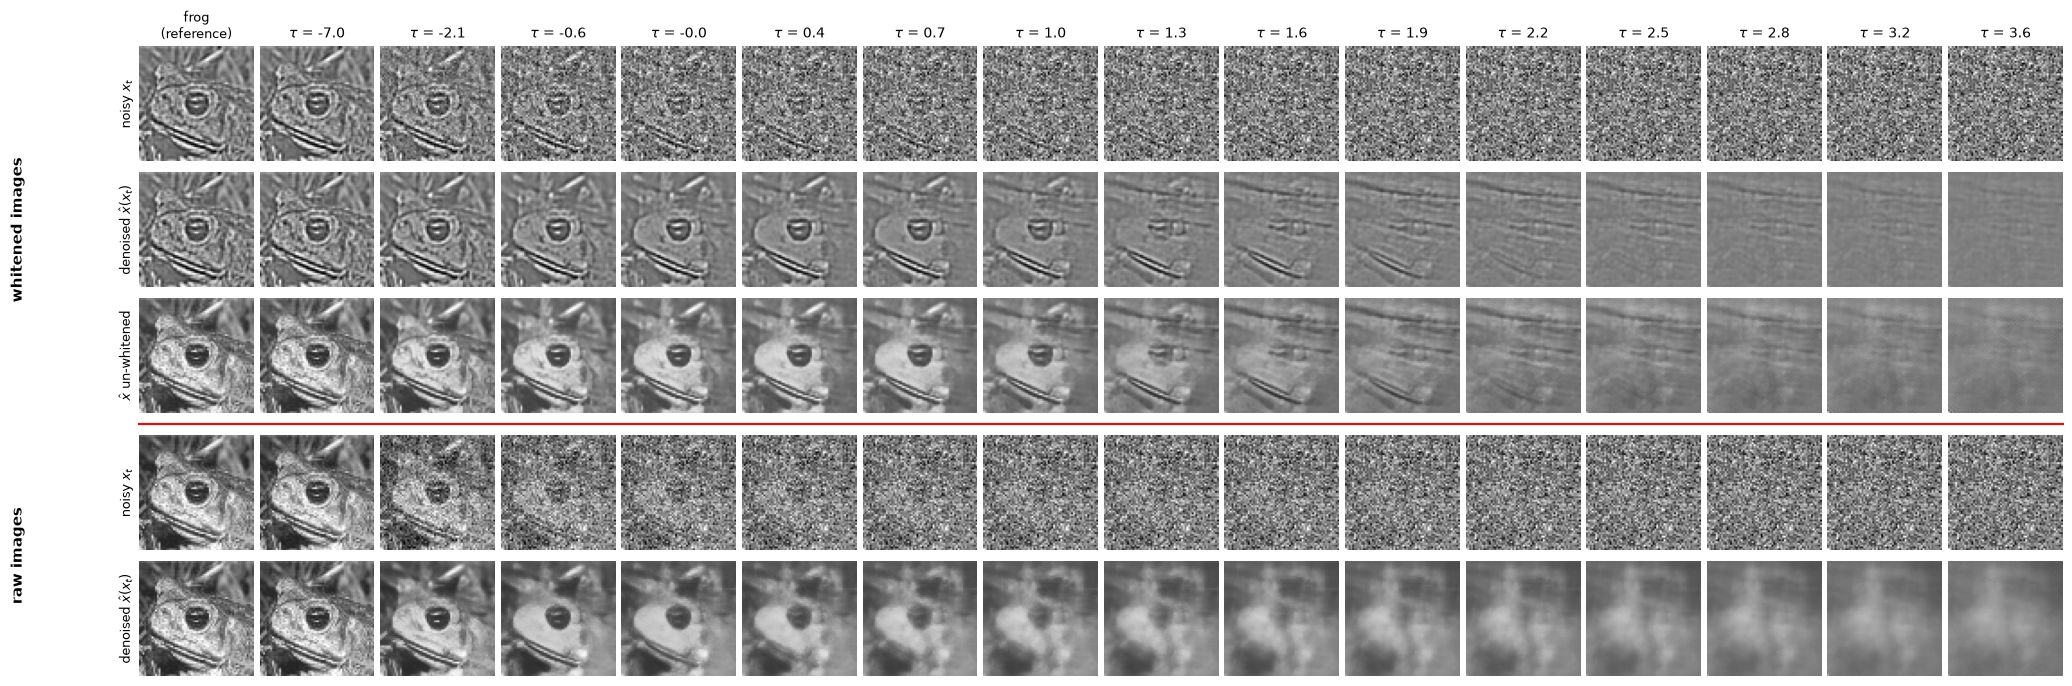

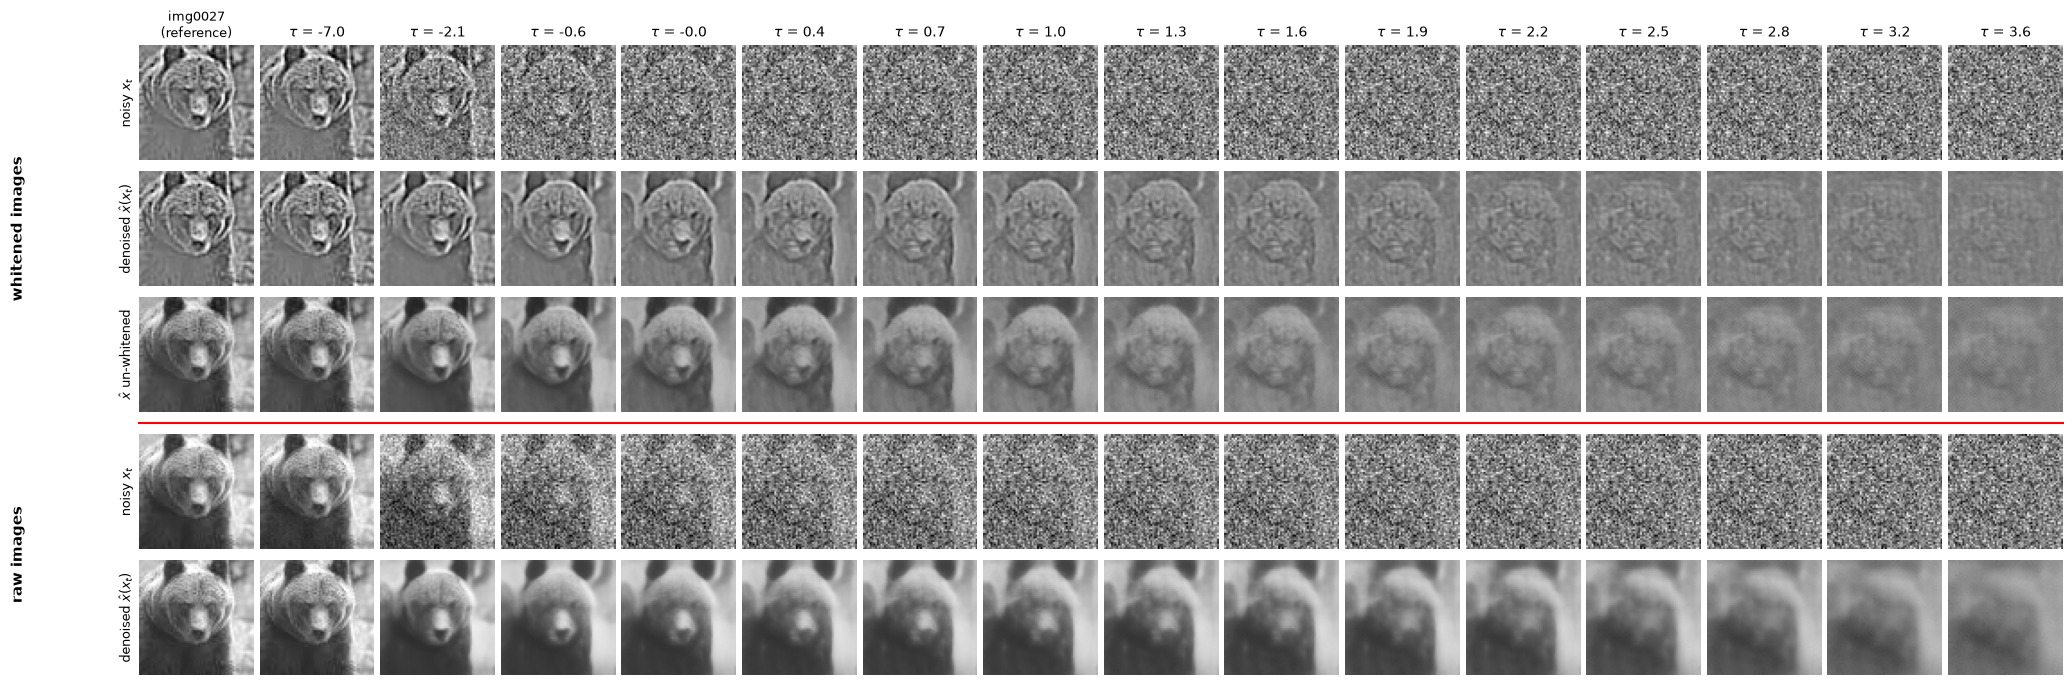

In [6]:
%%time

# one figure per image, saved; only those of PARAMS["show"] stay in the notebook
figure_dir = Path(PARAMS["figure_dir"])
figure_dir.mkdir(parents=True, exist_ok=True)
for name, (image, _) in examples.items():
    fig, _ = plot_whitened_vs_standard(
        image, whitening(image), references[name], rows[name], name, PARAMS
    )
    fig.savefig(
        figure_dir / f"xhat_whitened_vs_standard_{name}.png",
        dpi=PARAMS["file_dpi"],
        bbox_inches="tight",
    )
    if name not in PARAMS["show"]:
        plt.close(fig)
print(len(examples), "figures saved in", figure_dir)

## 6. Conclusion

* **What we computed.** For 20 images and 12 noise scales, the denoised image of the model of whitened images (un-whitened) and of the standard model, from the same noise; the figures are in `assets/figures/stimulus_whitening/v2/`.
* **The standard model recovers more of the image at every noise scale, and much more at coarse ones.** Mean correlation with the image (mean removed), whitened model un-whitened against standard model: 0.98 against 1.00 at $\tau = -7$, 0.93 against 0.94 at $-2.1$, 0.80 against 0.84 at 0, 0.64 against 0.78 at 1.0, 0.44 against 0.70 at 1.9, 0.27 against 0.60 at 2.8, and 0.18 against 0.50 at 3.6.
* **The image forms gradually.** With one noise draw per image for all noise scales, and noise scales every 0.3 from $\tau = 0.4$ to 3.2 (as in notebook 18), the denoised images change smoothly from one column to the next.
* **The two models fail differently.** As the noise grows, the standard model keeps the coarse layout of the image (light and dark regions) and loses the details; the model of whitened images keeps edges and fine structure longer in its denoised image, but loses the coarse layout, which whitening had weakened and the inverse filter must amplify back.
* **Next steps.** Compare the two models at matched signal-to-noise ratio per spatial frequency rather than per pixel: whitening moves the power of the images from low to high frequencies, so the same pixel noise hides their coarse structure sooner.